In [1]:
import os
os.environ.pop("REQUESTS_CA_BUNDLE", None)
os.environ.pop("CURL_CA_BUNDLE", None)

'C:\\Program Files\\PostgreSQL\\18\\ssl\\certs\\ca-bundle.crt'

In [2]:
import sys
print(sys.executable)

c:\Users\vova1\miniconda3\envs\f1\python.exe


In [3]:
import fastf1
fastf1.Cache.enable_cache('../cache')

In [4]:
session = fastf1.get_session(2024, "Monza", "R")
session.load()

core           INFO 	Loading data for Italian Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['16', '81', '4', '55', '44', '1', '63', '11', '23', '20', '14', '43', '3', '31', '10', '77', '27', '24', '18', '22']


In [5]:
import os
print(os.environ.get("REQUESTS_CA_BUNDLE"))
print(os.environ.get("CURL_CA_BUNDLE"))

None
None


In [6]:
laps = session.laps
laps.head()

,Time,Driver,DriverNumber,LapTime,LapNumber,Stint,PitOutTime,PitInTime,Sector1Time,Sector2Time,...,FreshTyre,Team,LapStartTime,LapStartDate,TrackStatus,Position,Deleted,DeletedReason,FastF1Generated,IsAccurate
0,0 days 00:57:18.931000,LEC,16,0 days 00:01:28.179000,1.0,1.0,NaT,NaT,NaT,0 days 00:00:29.989000,...,True,Ferrari,0 days 00:55:50.494000,2024-09-01 13:03:34.413,1,2.0,False,,False,False
1,0 days 00:58:44.327000,LEC,16,0 days 00:01:25.396000,2.0,1.0,NaT,NaT,0 days 00:00:27.707000,0 days 00:00:29.265000,...,True,Ferrari,0 days 00:57:18.931000,2024-09-01 13:05:02.850,1,2.0,False,,False,True
2,0 days 01:00:09.506000,LEC,16,0 days 00:01:25.179000,3.0,1.0,NaT,NaT,0 days 00:00:27.679000,0 days 00:00:29.001000,...,True,Ferrari,0 days 00:58:44.327000,2024-09-01 13:06:28.246,1,2.0,False,,False,True
3,0 days 01:01:34.316000,LEC,16,0 days 00:01:24.810000,4.0,1.0,NaT,NaT,0 days 00:00:27.653000,0 days 00:00:28.883000,...,True,Ferrari,0 days 01:00:09.506000,2024-09-01 13:07:53.425,1,2.0,False,,False,True
4,0 days 01:02:58.919000,LEC,16,0 days 00:01:24.603000,5.0,1.0,NaT,NaT,0 days 00:00:27.630000,0 days 00:00:28.790000,...,True,Ferrari,0 days 01:01:34.316000,2024-09-01 13:09:18.235,1,2.0,False,,False,True


In [7]:
laps.info()

<class 'fastf1.core.Laps'>
RangeIndex: 1008 entries, 0 to 1007
Data columns (total 31 columns):
 #   Column              Non-Null Count  Dtype          
---  ------              --------------  -----          
 0   Time                1008 non-null   timedelta64[ns]
 1   Driver              1008 non-null   object         
 2   DriverNumber        1008 non-null   object         
 3   LapTime             1008 non-null   timedelta64[ns]
 4   LapNumber           1008 non-null   float64        
 5   Stint               1008 non-null   float64        
 6   PitOutTime          30 non-null     timedelta64[ns]
 7   PitInTime           31 non-null     timedelta64[ns]
 8   Sector1Time         988 non-null    timedelta64[ns]
 9   Sector2Time         1008 non-null   timedelta64[ns]
 10  Sector3Time         1008 non-null   timedelta64[ns]
 11  Sector1SessionTime  985 non-null    timedelta64[ns]
 12  Sector2SessionTime  1008 non-null   timedelta64[ns]
 13  Sector3SessionTime  1008 non-null   timedelt

In [8]:
laps["Compound"].value_counts()

Compound
HARD      732
MEDIUM    274
SOFT        2
Name: count, dtype: int64

In [9]:
laps.isna().sum()


Time                    0
Driver                  0
DriverNumber            0
LapTime                 0
LapNumber               0
Stint                   0
PitOutTime            978
PitInTime             977
Sector1Time            20
Sector2Time             0
Sector3Time             0
Sector1SessionTime     23
Sector2SessionTime      0
Sector3SessionTime      0
SpeedI1                 0
SpeedI2                 0
SpeedFL                31
SpeedST                 0
IsPersonalBest          0
Compound                0
TyreLife                0
FreshTyre               0
Team                    0
LapStartTime            0
LapStartDate            0
TrackStatus             0
Position                0
Deleted                 0
DeletedReason           0
FastF1Generated         0
IsAccurate              0
dtype: int64

In [10]:
laps[laps["Sector1Time"].isna()]["LapNumber"].value_counts()

LapNumber
1.0    20
Name: count, dtype: int64

In [11]:
laps[laps["SpeedFL"].isna()]["PitInTime"].notna().sum()

np.int64(31)

In [12]:
laps.info(verbose=True, show_counts=True)

<class 'fastf1.core.Laps'>
RangeIndex: 1008 entries, 0 to 1007
Data columns (total 31 columns):
 #   Column              Non-Null Count  Dtype          
---  ------              --------------  -----          
 0   Time                1008 non-null   timedelta64[ns]
 1   Driver              1008 non-null   object         
 2   DriverNumber        1008 non-null   object         
 3   LapTime             1008 non-null   timedelta64[ns]
 4   LapNumber           1008 non-null   float64        
 5   Stint               1008 non-null   float64        
 6   PitOutTime          30 non-null     timedelta64[ns]
 7   PitInTime           31 non-null     timedelta64[ns]
 8   Sector1Time         988 non-null    timedelta64[ns]
 9   Sector2Time         1008 non-null   timedelta64[ns]
 10  Sector3Time         1008 non-null   timedelta64[ns]
 11  Sector1SessionTime  985 non-null    timedelta64[ns]
 12  Sector2SessionTime  1008 non-null   timedelta64[ns]
 13  Sector3SessionTime  1008 non-null   timedelt

In [13]:
laps["TrackStatus"].value_counts()

TrackStatus
1    1008
Name: count, dtype: int64

In [14]:
laps[["IsAccurate", "Deleted", "FastF1Generated"]].sum()

IsAccurate         927
Deleted             13
FastF1Generated      0
dtype: int64

In [15]:
mask = (
    (laps["LapNumber"] > 1)
    & laps["PitInTime"].isna()
    & laps["PitOutTime"].isna()
    & (laps["TrackStatus"] == "1")
    & laps["IsAccurate"]
    & ~laps["Deleted"]
    & ~laps["FastF1Generated"]
)
print(mask.sum(), "out of", len(laps))

914 out of 1008


In [16]:
filters = {
    "lap 1": laps["LapNumber"] == 1,
    "pit in": laps["PitInTime"].notna(),
    "pit out": laps["PitOutTime"].notna(),
    "not green flag": laps["TrackStatus"] != "1",
    "inaccurate": ~laps["IsAccurate"],
    "deleted": laps["Deleted"],
}

for name, cond in filters.items():
    print(f"{name:15} {cond.sum()}")

lap 1           20
pit in          31
pit out         30
not green flag  0
inaccurate      81
deleted         13


In [17]:
clean = laps[mask].copy()
clean["LapTimeSec"] = clean["LapTime"].dt.total_seconds()
clean[["Driver", "LapNumber", "LapTime", "LapTimeSec"]].head()

,Driver,LapNumber,LapTime,LapTimeSec
1,LEC,2.0,0 days 00:01:25.396000,85.396
2,LEC,3.0,0 days 00:01:25.179000,85.179
3,LEC,4.0,0 days 00:01:24.810000,84.810
4,LEC,5.0,0 days 00:01:24.603000,84.603
5,LEC,6.0,0 days 00:01:24.663000,84.663


In [18]:
clean["LapTimeSec"].describe()

count    914.000000
mean      84.784802
std        1.247637
min       81.432000
25%       83.756500
50%       84.844000
75%       85.660500
max       89.256000
Name: LapTimeSec, dtype: float64

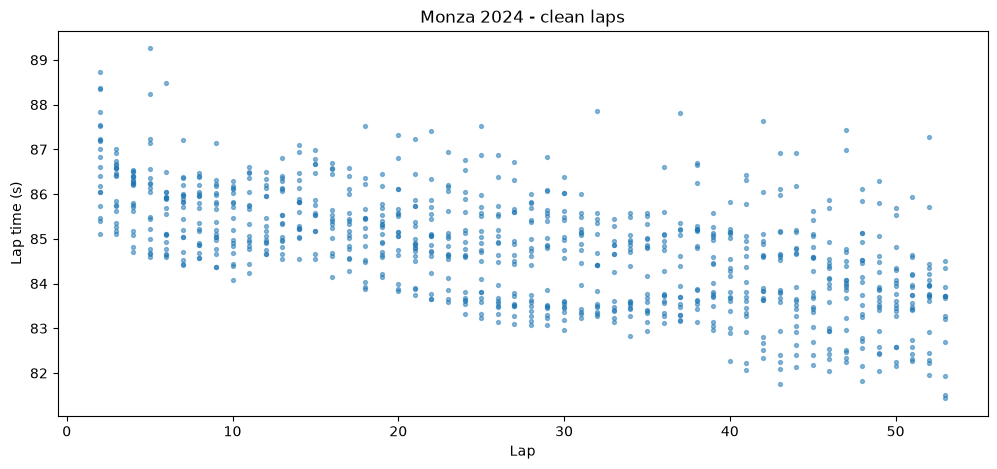

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.scatter(clean["LapNumber"], clean["LapTimeSec"], s=8, alpha=0.5)
plt.xlabel("Lap")
plt.ylabel("Lap time (s)")
plt.title("Monza 2024 - clean laps")
plt.show()

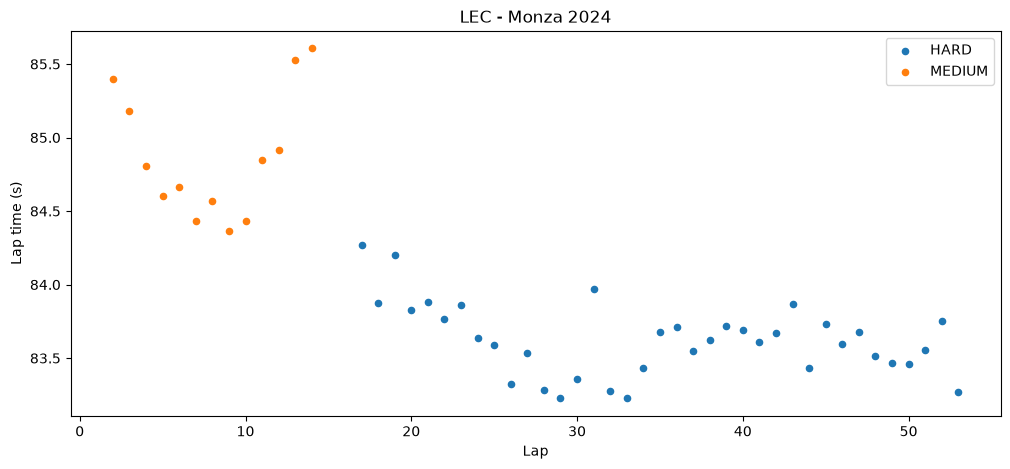

In [20]:
lec = clean[clean["Driver"] == "LEC"]

plt.figure(figsize=(12, 5))
for compound, group in lec.groupby("Compound"):
    plt.scatter(group["LapNumber"], group["LapTimeSec"], label=compound, s=20)
plt.xlabel("Lap")
plt.ylabel("Lap time (s)")
plt.title("LEC - Monza 2024")
plt.legend()
plt.show()

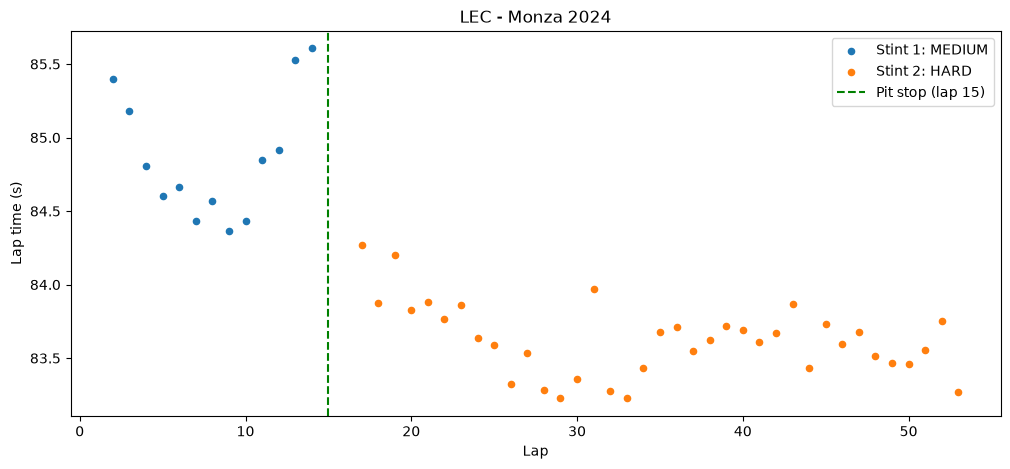

In [21]:
laps[laps["Driver"] == "LEC"][["Stint", "Compound"]].drop_duplicates()
lec_all = laps[laps["Driver"] == "LEC"]
pit_laps = lec_all[lec_all["PitInTime"].notna()]["LapNumber"]
plt.figure(figsize=(12, 5))
for (stint, compound), group in lec.groupby(["Stint", "Compound"]):
    plt.scatter(group["LapNumber"], group["LapTimeSec"],
                label=f"Stint {int(stint)}: {compound}", s=20)

for lap in pit_laps:
    plt.axvline(lap, color="green", linestyle="--", label=f"Pit stop (lap {int(lap)})")

plt.xlabel("Lap")
plt.ylabel("Lap time (s)")
plt.title("LEC - Monza 2024")
plt.legend()
plt.show()

In [22]:
import sys
import os

sys.path.append(os.path.abspath(".."))
print(os.getcwd())
from src.clean import clean_laps

clean = clean_laps(session.laps)
print(clean.shape)
clean.to_parquet("../data/processed/monza_2024_clean.parquet")

c:\Users\vova1\Documents\vscodefiles\resume projects\f1 project\notebooks
(914, 32)


In [23]:
from src.ingest import load_race

monza = load_race(2024, 16)
print(monza.shape)
monza[["Event", "Year", "Round", "Driver", "LapNumber", "LapTimeSec"]].head()

(914, 35)


,Event,Year,Round,Driver,LapNumber,LapTimeSec
1,Italian Grand Prix,2024,16,LEC,2.0,85.396
2,Italian Grand Prix,2024,16,LEC,3.0,85.179
3,Italian Grand Prix,2024,16,LEC,4.0,84.810
4,Italian Grand Prix,2024,16,LEC,5.0,84.603
5,Italian Grand Prix,2024,16,LEC,6.0,84.663


In [24]:
print(monza.shape)
print(monza["Deleted"].sum())

(914, 35)
0


In [25]:
from src.ingest import load_season

season = load_season(2024, max_rounds=3)
print(season.shape)
season["Event"].value_counts()

2024 R1: 988 laps
2024 R2: 786 laps
2024 R3: 851 laps
(2625, 35)


Event
Bahrain Grand Prix          988
Australian Grand Prix       851
Saudi Arabian Grand Prix    786
Name: count, dtype: int64

In [ ]:
for year in [2022, 2023, 2024, 2025]:
    season = load_season(year)
    season.to_parquet(f"../data/processed/laps_{year}.parquet")
    print(f"=== {year}: {season.shape} saved ===")

In [27]:
from pathlib import Path
from src.ingest import ingest_season

races_dir = Path("../data/processed/races")

for year in [2022, 2023, 2024, 2025]:
    finished = ingest_season(year, races_dir)
    if not finished:
        break

Request for URL https://raw.githubusercontent.com/theOehrly/f1schedule/master/schedule_2022.json failed; using cached response
Traceback (most recent call last):
  File "c:\Users\vova1\miniconda3\envs\f1\Lib\site-packages\requests_cache\session.py", line 311, in _resend
    response = self._send_and_cache(request, actions, cached_response, **kwargs)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\vova1\miniconda3\envs\f1\Lib\site-packages\requests_cache\session.py", line 279, in _send_and_cache
    response = super().send(request, **kwargs)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\vova1\miniconda3\envs\f1\Lib\site-packages\fastf1\req.py", line 110, in send
    lim.limit()
  File "c:\Users\vova1\miniconda3\envs\f1\Lib\site-packages\fastf1\req.py", line 80, in limit
    raise RateLimitExceededError(self._info)
fastf1.exceptions.RateLimitExceededError: any API: 500 calls/h
Request for URL https://raw.githubuserconten

2022 R1: 854 laps saved


core        WARNING 	No lap data for driver 22
core        WARNING 	Failed to perform lap accuracy check - all laps marked as inaccurate (driver 22)
core        WARNING 	Failed to perform lap accuracy check - all laps marked as inaccurate (driver 47)
Request for URL https://api.jolpi.ca/ergast/f1/2022/2/laps/1.json failed; using cached response
Traceback (most recent call last):
  File "c:\Users\vova1\miniconda3\envs\f1\Lib\site-packages\requests_cache\session.py", line 311, in _resend
    response = self._send_and_cache(request, actions, cached_response, **kwargs)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\vova1\miniconda3\envs\f1\Lib\site-packages\requests_cache\session.py", line 279, in _send_and_cache
    response = super().send(request, **kwargs)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\vova1\miniconda3\envs\f1\Lib\site-packages\fastf1\req.py", line 110, in send
    lim.limit()
  File "c:\Users\vova1\min

2022 R2: 588 laps saved


Request for URL https://api.jolpi.ca/ergast/f1/2022/3/results.json failed; using cached response
Traceback (most recent call last):
  File "c:\Users\vova1\miniconda3\envs\f1\Lib\site-packages\requests_cache\session.py", line 311, in _resend
    response = self._send_and_cache(request, actions, cached_response, **kwargs)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\vova1\miniconda3\envs\f1\Lib\site-packages\requests_cache\session.py", line 279, in _send_and_cache
    response = super().send(request, **kwargs)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\vova1\miniconda3\envs\f1\Lib\site-packages\fastf1\req.py", line 110, in send
    lim.limit()
  File "c:\Users\vova1\miniconda3\envs\f1\Lib\site-packages\fastf1\req.py", line 80, in limit
    raise RateLimitExceededError(self._info)
fastf1.exceptions.RateLimitExceededError: any API: 500 calls/h
Request for URL https://api.jolpi.ca/ergast/f1/2022/3/laps/1.json failed; 

...

2025 R11: 984 laps saved


core        WARNING 	Failed to perform lap accuracy check - all laps marked as inaccurate (driver 43)
core        WARNING 	Fixed incorrect tyre stint information for driver '81'
core        WARNING 	Fixed incorrect tyre stint information for driver '4'


2025 R12: 435 laps saved


core        WARNING 	Fixed incorrect tyre stint information for driver '16'
core        WARNING 	Fixed incorrect tyre stint information for driver '1'
core        WARNING 	Fixed incorrect tyre stint information for driver '63'
core        WARNING 	Fixed incorrect tyre stint information for driver '23'
core        WARNING 	Fixed incorrect tyre stint information for driver '44'
core        WARNING 	Fixed incorrect tyre stint information for driver '30'
core        WARNING 	Fixed incorrect tyre stint information for driver '5'
core        WARNING 	Fixed incorrect tyre stint information for driver '10'
core        WARNING 	Fixed incorrect tyre stint information for driver '87'
core        WARNING 	Fixed incorrect tyre stint information for driver '27'
core        WARNING 	Fixed incorrect tyre stint information for driver '22'
core        WARNING 	Fixed incorrect tyre stint information for driver '18'
core        WARNING 	Fixed incorrect tyre stint information for driver '31'
core        WA

2025 R13: 734 laps saved
2025 R14: 1275 laps saved
2025 R15: 998 laps saved
Rate limit hit at 2025 R16. Rerun in ~1 hour.
